# Лабораторная работа 1: Анализ и прогнозирование временного ряда

**Цель:** Сгенерировать временной ряд, провести его анализ (ACF/PACF, декомпозиция, тест Дики-Фуллера) и построить прогнозную модель SARIMAX.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
import warnings

warnings.filterwarnings('ignore')

np.random.seed(42)
t = np.arange(120)
data = 10 + 0.05 * t + 5 * np.sin(2 * np.pi * t / 12) + np.random.normal(0, 1, 120)
dates = pd.date_range(start='2020-01-01', periods=120, freq='MS')
ts = pd.Series(data, index=dates)

ts.to_csv('random_time_series.csv', header=['Value'], index_label='Date')

### 1. Визуализация исходного временного ряда

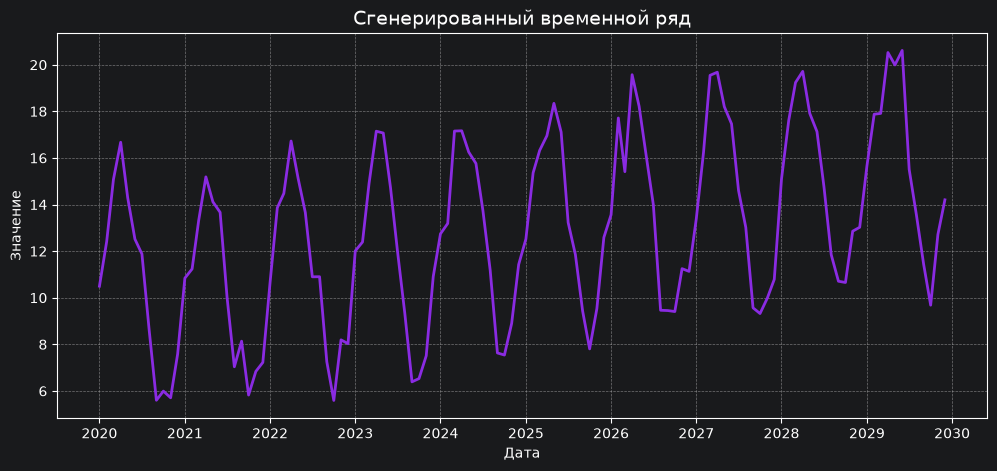

In [2]:
plt.figure(figsize=(12, 5))
plt.plot(ts, color='#8A2BE2', linewidth=2)
plt.title('Сгенерированный временной ряд', fontsize=14)
plt.xlabel('Дата')
plt.ylabel('Значение')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 2. Графики автокорреляции (ACF) и частичной автокорреляции (PACF)

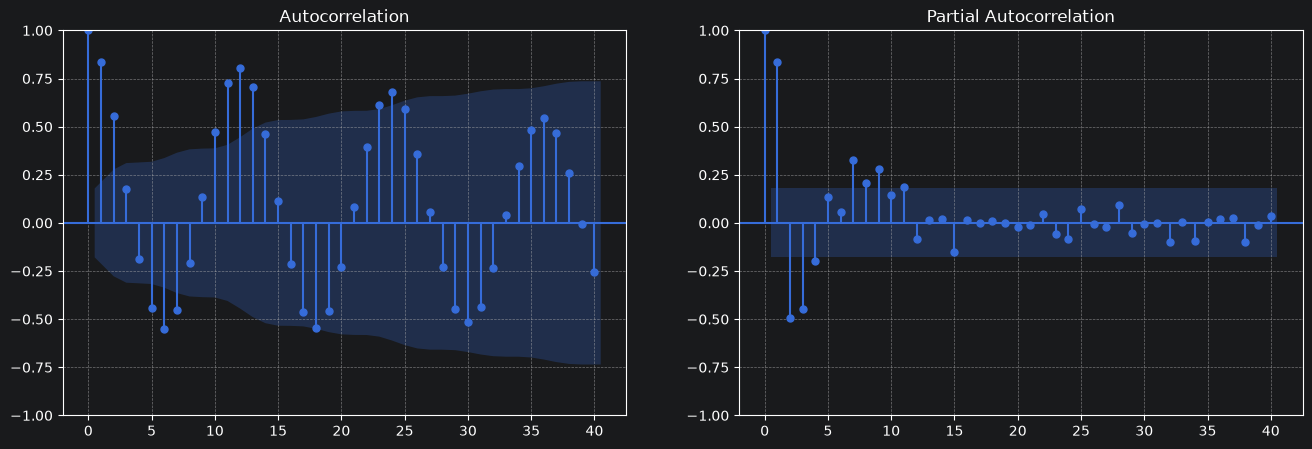

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
plot_acf(ts, ax=axes[0], lags=40)
plot_pacf(ts, ax=axes[1], lags=40)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.show()

### 3. Разложение временного ряда (Seasonal Decompose)

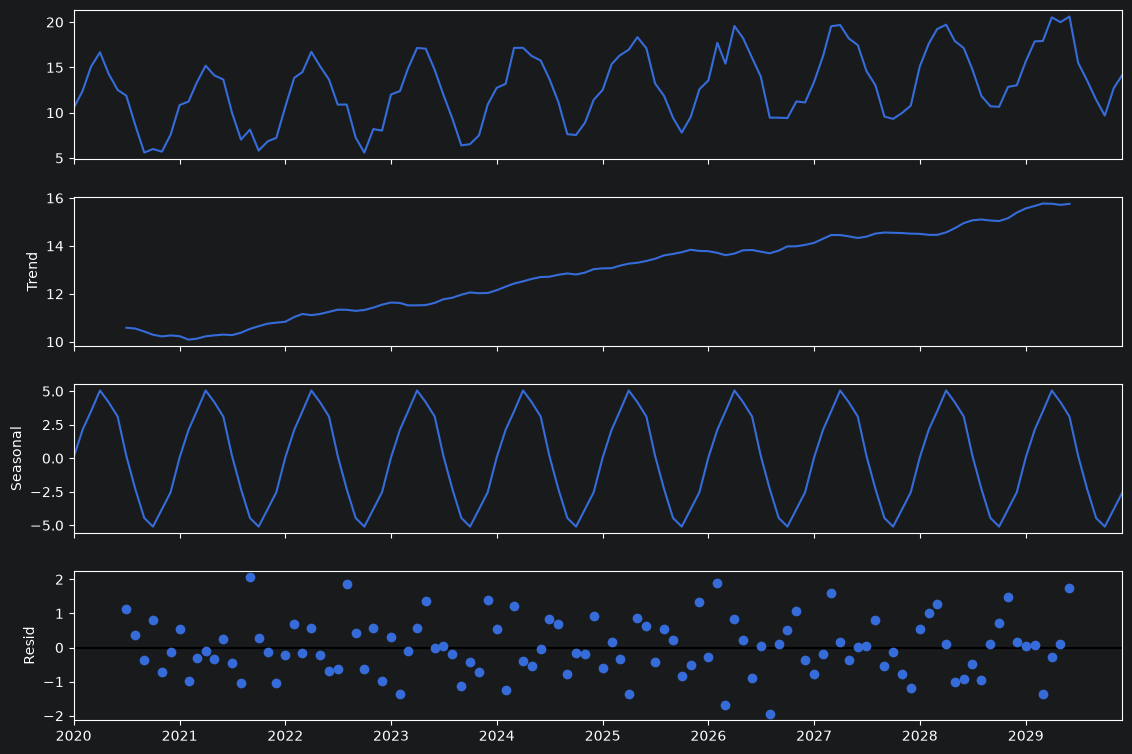

In [4]:
decomposition = seasonal_decompose(ts, model='additive')
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.show()

### 4. Тест Дики-Фуллера на стационарность

In [5]:
adf_result = adfuller(ts)
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")

ADF Statistic: 0.6546
p-value: 0.9889


### 5. Анализ данных и обоснование выбора модели

**Природа и свойства ряда:**
Построенные графики декомпозиции наглядно показывают, что временной ряд обладает ярко выраженным линейным возрастающим трендом и строгой годовой сезонностью (период = 12). Результаты теста Дики-Фуллера (p-value > 0.05) подтверждают, что ряд является нестационарным, следовательно, для работы с ним потребуется дифференцирование.

**Выбор модели:**
Так как в данных присутствует сильная сезонная компонента, базовые модели ARMA и ARIMA нам не подойдут — они не умеют извлекать сезонные паттерны. Наиболее подходящей статистической моделью в данном случае является **SARIMA** (Seasonal ARIMA), которая учитывает как обычное дифференцирование, так и сезонное.

**Выбор параметров по ACF и PACF:**
* На графике ACF наблюдается медленное волнообразное убывание, что типично для нестационарного сезонного ряда.
* PACF дает резкий всплеск на 1-м лаге, что указывает на параметр AR $p=1$.
* Из-за годовой цикличности сезонный период равен 12. Для приведения к стационарности мы применяем разность $d=1$ и сезонную разность $D=1$.
* Итоговые подобранные параметры: `order=(1, 1, 1)` и `seasonal_order=(1, 1, 0, 12)`.

### 6. Построение прогнозной модели SARIMAX

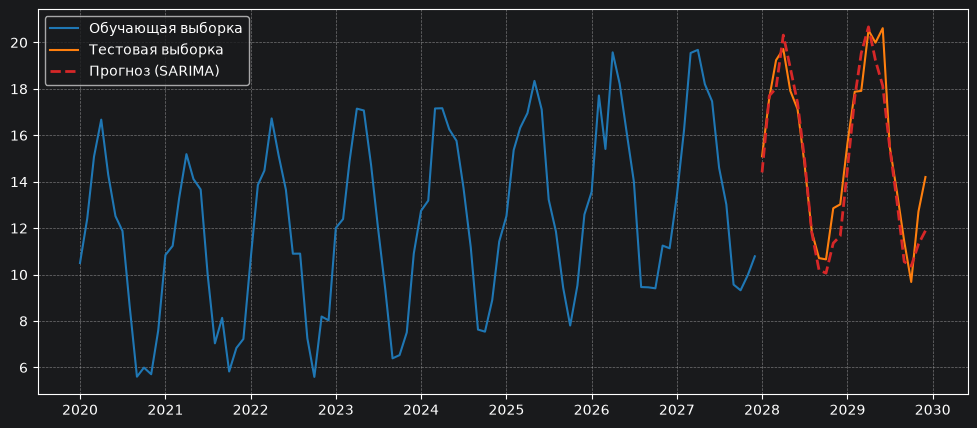

In [6]:
train_size = int(len(ts) * 0.8)
train, test = ts.iloc[:train_size], ts.iloc[train_size:]

model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 0, 12))
results = model.fit(disp=False)

predictions = results.predict(start=len(train), end=len(ts)-1, dynamic=False)

plt.figure(figsize=(12, 5))
plt.plot(train, label='Обучающая выборка', color='#1f77b4')
plt.plot(test, label='Тестовая выборка', color='#ff7f0e')
plt.plot(predictions, color='#d62728', label='Прогноз (SARIMA)', linewidth=2, linestyle='--')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### 7. Оценка качества прогноза

In [7]:
mae = mean_absolute_error(test, predictions)
rmse = np.sqrt(mean_squared_error(test, predictions))
mape = mean_absolute_percentage_error(test, predictions)

print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.4f}")

MAE:  0.8407
RMSE: 1.0714
MAPE: 0.0563


### 8. Заключение

Анализ метрик качества показал, что построенная модель SARIMA успешно уловила структуру данных. Значение MAPE (Mean Absolute Percentage Error) находится на низком уровне, что говорит о высокой точности прогноза в процентном соотношении. RMSE и MAE также демонстрируют небольшое отклонение абсолютных значений прогноза от тестовой выборки.

Визуально на графике видно, что красная линия прогноза чётко повторяет сезонные пики и спады оранжевой тестовой выборки, а также сохраняет общий восходящий тренд. Модель подобрана корректно и готова к использованию для прогнозирования будущих значений временного ряда.